# Daily Challenge: Text Analysis of books using word clouds

**What you'll learn:** text preprocessing · text analysis · Bag of Words (BoW) · TF-IDF

**Corpus:** three books by Lewis Carroll from Project Gutenberg:
- *Alice's Adventures in Wonderland* (pg11)
- *Through the Looking-Glass, and What Alice Found There* (pg12)
- *A Tangled Tale* (pg29042)

> **Environment:** locally this course should be run in a dedicated virtual environment, for example `python -m venv nlp-env && source nlp-env/bin/activate && pip install nltk spacy wordcloud scikit-learn matplotlib requests`. On Colab the cell below installs what is missing.

In [1]:
%pip install --quiet nltk spacy wordcloud scikit-learn matplotlib requests

Note: you may need to restart the kernel to use updated packages.


In [2]:
import re
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import spacy
from collections import Counter

for res in ["punkt", "punkt_tab", "stopwords", "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng",
            "maxent_ne_chunker", "maxent_ne_chunker_tab", "words"]:
    nltk.download(res, quiet=True)

try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    from spacy.cli import download
    download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

print("nltk", nltk.__version__, "| spaCy", spacy.__version__)

nltk 3.10.3 | spaCy 3.8.16


# Part 1 · Text preprocessing

### 1. `load_texts()`: download the books and clean non-words
The function downloads each URL with `requests`, then uses regular expressions to:
- normalise typographic apostrophes (`’` → `'`) so that `Alice’s` stays one word;
- replace every character that is not a letter, an apostrophe or a line break with a space (digits, punctuation, `*`, `_`, `“ ”`, `—` …);
- drop apostrophes that are not inside a word (quotation marks such as `'Off with her head!'`);
- collapse repeated spaces.

Line breaks are kept on purpose, so that the Gutenberg header and footer lines can still be located in step 2.

In [3]:
URLS = {
    "Alice's Adventures in Wonderland": "https://www.gutenberg.org/cache/epub/11/pg11.txt",
    "Through the Looking-Glass": "https://www.gutenberg.org/cache/epub/12/pg12.txt",
    "A Tangled Tale": "https://www.gutenberg.org/cache/epub/29042/pg29042.txt",
}
TITLES = list(URLS)

def clean_text(text):
    text = text.replace("\ufeff", "").replace("’", "'").replace("‘", "'")
    text = re.sub(r"[^A-Za-z'\n]", " ", text)              # keep only letters, apostrophes and newlines
    text = re.sub(r"(?<![A-Za-z])'|'(?![A-Za-z])", " ", text)  # apostrophes that are quotation marks
    text = re.sub(r"[ \t]+", " ", text)                      # collapse spaces
    text = re.sub(r" *\n *", "\n", text)
    return text.strip()

import time
from functools import lru_cache

@lru_cache(maxsize=None)
def fetch(url, retries=4):
    # download a text with requests (cached, with a few retries if the connection drops)
    for attempt in range(retries):
        try:
            response = requests.get(url, timeout=60)
            response.raise_for_status()
            response.encoding = "utf-8"
            return response.text
        except requests.RequestException:
            if attempt == retries - 1:
                raise
            time.sleep(2 ** (attempt + 1))

def load_texts(urls):
    corpus = []
    for url in urls:
        corpus.append(clean_text(fetch(url)))
    return corpus

corpus = load_texts(URLS.values())
for title, text in zip(TITLES, corpus):
    print(f"{title:35s}: {len(text):7d} characters")

Alice's Adventures in Wonderland   :  154839 characters
Through the Looking-Glass          :  172100 characters
A Tangled Tale                     :  163648 characters


### 2. First 200 characters of each text

In [4]:
for title, text in zip(TITLES, corpus):
    print(f"--- {title}\n{text[:200]!r}\n")

--- Alice's Adventures in Wonderland
"The Project Gutenberg eBook of Alice's Adventures in Wonderland\n\nThis eBook is for the use of anyone anywhere in the United States and\nmost other parts of the world at no cost and with almost no restr"

--- Through the Looking-Glass
'The Project Gutenberg eBook of Through the Looking Glass\n\nThis eBook is for the use of anyone anywhere in the United States and\nmost other parts of the world at no cost and with almost no restrictions'

--- A Tangled Tale
'The Project Gutenberg eBook of A Tangled Tale\n\nThis eBook is for the use of anyone anywhere in the United States and\nmost other parts of the world at no cost and with almost no restrictions\nwhatsoever'



**Yes, there are irrelevant parts.** Each file starts with the Project Gutenberg header ("The Project Gutenberg eBook of …", "This ebook is for the use of anyone anywhere…", release date, language, credits) and ends with about 350 lines of licence text (the "Project Gutenberg License", donation info…). These words (*Project*, *Gutenberg*, *electronic*, *work*, *license*, *foundation*…) would pollute the word counts; the example word cloud of the exercise even shows "Project Gutenberg" and "electronic work".

We keep only the text between the line containing ` START` (`*** START OF THE PROJECT GUTENBERG EBOOK … ***`) and the line containing ` END` (`*** END OF THE PROJECT GUTENBERG EBOOK … ***`). The stars were removed by the cleaning, so we search for the phrases `START OF THE PROJECT GUTENBERG EBOOK` and `END OF THE PROJECT GUTENBERG EBOOK`. *A Tangled Tale* also has a producer credit and a transcriber's note right after the START marker, and publisher advertisements plus a list of printer corrections after the final `THE END`. We remove those too, as well as the `[Illustration]` placeholders that Gutenberg inserts in place of pictures.

In [5]:
START_MARK = "START OF THE PROJECT GUTENBERG EBOOK"
END_MARK = "END OF THE PROJECT GUTENBERG EBOOK"

def trim_gutenberg(text):
    start = text.find(START_MARK)
    start = text.find("\n", start) + 1          # skip the rest of the START line (the title)
    end = text.find(END_MARK)
    body = text[start:end].strip()
    # A Tangled Tale: drop the producer credit + transcriber's note before the actual title page
    if "Transcriber's note" in body[:1000]:
        body = body[body.find("A TANGLED TALE"):]
    # every book finishes with "THE END": what follows (publisher ads, list of corrections) is not part of the story
    if "THE END" in body:
        body = body[:body.rfind("THE END")]
    # Gutenberg placeholders for pictures
    body = re.sub(r"\b(Illustration|Decoration|Frontispiece)\b", " ", body)
    return body.strip()

books = [trim_gutenberg(t) for t in corpus]
for title, raw, book in zip(TITLES, corpus, books):
    print(f"--- {title}: {len(raw)} -> {len(book)} characters")
    print(repr(book[:200]))
    print("... ends with:", repr(book[-120:]), "\n")

--- Alice's Adventures in Wonderland: 154839 -> 136377 characters
"Alice's Adventures in Wonderland\n\nby Lewis Carroll\n\nTHE MILLENNIUM FULCRUM EDITION\n\nContents\n\nCHAPTER I Down the Rabbit Hole\nCHAPTER II The Pool of Tears\nCHAPTER III A Caucus Race and a Long Tale\nCHAP"
... ends with: 'eir simple sorrows and find a pleasure in all\ntheir simple joys remembering her own child life and the happy summer\ndays' 

--- Through the Looking-Glass: 172100 -> 153674 characters
'THROUGH THE LOOKING GLASS\n\nAnd What Alice Found There\n\nBy Lewis Carroll\n\nThe Millennium Fulcrum Edition\n\n\n\n\nDRAMATIS PERSON\nAs arranged before commencement of game\n\nWHITE RED\nPIECES PAWNS PAWNS PIECES'
... ends with: ' by\nDreaming as the summers die\n\nEver drifting down the stream\nLingering in the golden gleam\nLife what is it but a dream' 

--- A Tangled Tale: 163648 -> 142657 characters
'A TANGLED TALE\n\n \n\n  AT A PACE OF SIX MILES IN THE HOUR\n\n \n\n\n\n\nA TANGLED TALE\n\nBY\n\nLEWIS CAR

### 3. Tokenization: first 150 tokens of each book

In [6]:
from nltk.tokenize import word_tokenize

tokens = [word_tokenize(book) for book in books]
for title, toks in zip(TITLES, tokens):
    print(f"--- {title}: {len(toks)} tokens")
    print(toks[:150], "\n")

--- Alice's Adventures in Wonderland: 27421 tokens
['Alice', "'s", 'Adventures', 'in', 'Wonderland', 'by', 'Lewis', 'Carroll', 'THE', 'MILLENNIUM', 'FULCRUM', 'EDITION', 'Contents', 'CHAPTER', 'I', 'Down', 'the', 'Rabbit', 'Hole', 'CHAPTER', 'II', 'The', 'Pool', 'of', 'Tears', 'CHAPTER', 'III', 'A', 'Caucus', 'Race', 'and', 'a', 'Long', 'Tale', 'CHAPTER', 'IV', 'The', 'Rabbit', 'Sends', 'in', 'a', 'Little', 'Bill', 'CHAPTER', 'V', 'Advice', 'from', 'a', 'Caterpillar', 'CHAPTER', 'VI', 'Pig', 'and', 'Pepper', 'CHAPTER', 'VII', 'A', 'Mad', 'Tea', 'Party', 'CHAPTER', 'VIII', 'The', 'Queen', "'s", 'Croquet', 'Ground', 'CHAPTER', 'IX', 'The', 'Mock', 'Turtle', "'s", 'Story', 'CHAPTER', 'X', 'The', 'Lobster', 'Quadrille', 'CHAPTER', 'XI', 'Who', 'Stole', 'the', 'Tarts', 'CHAPTER', 'XII', 'Alice', "'s", 'Evidence', 'CHAPTER', 'I', 'Down', 'the', 'Rabbit', 'Hole', 'Alice', 'was', 'beginning', 'to', 'get', 'very', 'tired', 'of', 'sitting', 'by', 'her', 'sister', 'on', 'the', 'bank', 'and', 'of'

### 4. Remove stopwords (NLTK)
We lowercase the tokens first (the stopword list is lowercase, so `I` and `The` would otherwise survive). NLTK's word tokenizer also splits contractions into pieces such as `n't`, `'s`, `'ll`, `'m`, `'ve`. These pieces are not in the stopword list, so we drop them as well, together with one-letter tokens.

In [7]:
from nltk.corpus import stopwords
stop_words = set(stopwords.words("english"))

def remove_stopwords(toks):
    return [t for t in (w.lower() for w in toks)
            if t not in stop_words and "'" not in t and len(t) > 1]

tokens_lower = [[t.lower() for t in toks] for toks in tokens]
tokens_nostop = [remove_stopwords(toks) for toks in tokens]

check = ["i", "me", "my", "myself", "we", "our", "ours", "ourselves", "the", "and", "she", "it"]
rows = []
for title, before, after in zip(TITLES, tokens_lower, tokens_nostop):
    rows.append({"book": title, "tokens before": len(before), "tokens after": len(after),
                 **{f"'{w}' before/after": f"{before.count(w)} / {after.count(w)}" for w in check}})
pd.DataFrame(rows).set_index("book").T

book,Alice's Adventures in Wonderland,Through the Looking-Glass,A Tangled Tale
tokens before,27421,31088,27435
tokens after,12369,14152,13316
'i' before/after,546 / 0,662 / 0,395 / 0
'me' before/after,68 / 0,96 / 0,53 / 0
'my' before/after,58 / 0,77 / 0,75 / 0
'myself' before/after,7 / 0,7 / 0,4 / 0
'we' before/after,34 / 0,54 / 0,124 / 0
'our' before/after,8 / 0,12 / 0,27 / 0
'ours' before/after,1 / 0,0 / 0,0 / 0
'ourselves' before/after,1 / 0,0 / 0,1 / 0


### 5. Stemming: `PorterStemmer`, first 50 stemmed tokens

In [8]:
from nltk.stem import PorterStemmer
stemmer = PorterStemmer()

stemmed = [[stemmer.stem(t) for t in toks] for toks in tokens_nostop]
for title, toks, st in zip(TITLES, tokens_nostop, stemmed):
    print(f"--- {title}")
    print(st[:50], "\n")

--- Alice's Adventures in Wonderland
['alic', 'adventur', 'wonderland', 'lewi', 'carrol', 'millennium', 'fulcrum', 'edit', 'content', 'chapter', 'rabbit', 'hole', 'chapter', 'ii', 'pool', 'tear', 'chapter', 'iii', 'caucu', 'race', 'long', 'tale', 'chapter', 'iv', 'rabbit', 'send', 'littl', 'bill', 'chapter', 'advic', 'caterpillar', 'chapter', 'vi', 'pig', 'pepper', 'chapter', 'vii', 'mad', 'tea', 'parti', 'chapter', 'viii', 'queen', 'croquet', 'ground', 'chapter', 'ix', 'mock', 'turtl', 'stori'] 

--- Through the Looking-Glass
['look', 'glass', 'alic', 'found', 'lewi', 'carrol', 'millennium', 'fulcrum', 'edit', 'dramati', 'person', 'arrang', 'commenc', 'game', 'white', 'red', 'piec', 'pawn', 'pawn', 'piec', 'tweedlede', 'daisi', 'daisi', 'humpti', 'dumpti', 'unicorn', 'haigha', 'messeng', 'carpent', 'sheep', 'oyster', 'oyster', 'walru', 'queen', 'lili', 'tiger', 'lili', 'queen', 'king', 'fawn', 'rose', 'king', 'age', 'man', 'oyster', 'oyster', 'crow', 'knight', 'hatta', 'frog'] 

--- A

### 6. Lemmatization with spaCy `en_core_web_sm`
The lemma is available as the `token.lemma_` attribute. spaCy's lemmatizer depends on the POS tagger, so we run the pipeline on the **trimmed text with its original casing and sentence structure**. Then we apply the same filters (lowercase, no stopwords, letters only) so that the result can be compared with the stems. The parser and NER components are disabled for speed.

In [9]:
nlp.max_length = 2_000_000
lemmatized = []
for title, book in zip(TITLES, books):
    doc = nlp(book.replace("\n", " "), disable=["parser", "ner"])
    lemmas = [tok.lemma_.lower() for tok in doc
              if tok.is_alpha and tok.lemma_.lower() not in stop_words and len(tok.lemma_) > 1]
    lemmatized.append(lemmas)
    print(f"--- {title}: {len(lemmas)} lemmas")
    print(lemmas[:50], "\n")

--- Alice's Adventures in Wonderland: 12282 lemmas
['alice', 'adventures', 'wonderland', 'lewis', 'carroll', 'millennium', 'fulcrum', 'edition', 'content', 'chapter', 'rabbit', 'hole', 'chapter', 'ii', 'pool', 'tears', 'chapter', 'iii', 'caucus', 'race', 'long', 'tale', 'chapter', 'iv', 'rabbit', 'send', 'little', 'bill', 'chapter', 'advice', 'caterpillar', 'chapter', 'vi', 'pig', 'pepper', 'chapter', 'vii', 'mad', 'tea', 'party', 'chapter', 'viii', 'queen', 'croquet', 'ground', 'chapter', 'ix', 'mock', 'turtle', 'story'] 



--- Through the Looking-Glass: 14075 lemmas
['looking', 'glass', 'alice', 'find', 'lewis', 'carroll', 'millennium', 'fulcrum', 'edition', 'dramatis', 'person', 'arrange', 'commencement', 'game', 'white', 'red', 'piece', 'pawns', 'pawns', 'pieces', 'tweedledee', 'daisy', 'daisy', 'humpty', 'dumpty', 'unicorn', 'haigha', 'messenger', 'carpenter', 'sheep', 'oyster', 'oyster', 'walrus', 'queen', 'lily', 'tiger', 'lily', 'queen', 'king', 'fawn', 'rose', 'king', 'aged', 'man', 'oyster', 'oyster', 'crow', 'knight', 'hatta', 'frog'] 



--- A Tangled Tale: 13249 lemmas
['tangle', 'tale', 'pace', 'six', 'mile', 'hour', 'tangle', 'tale', 'lewis', 'carroll', 'six', 'illustration', 'arthur', 'frost', 'hoc', 'meum', 'tale', 'quale', 'est', 'accipe', 'second', 'thousand', 'london', 'macmillan', 'co', 'rights', 'reserved', 'richard', 'clay', 'sons', 'bread', 'street', 'hill', 'london', 'bungay', 'suffolk', 'pupil', 'beloved', 'pupil', 'tame', 'thee', 'addish', 'subtrac', 'multiplica', 'tion', 'division', 'fractions', 'rule', 'three', 'attest'] 



### 7. Stemmed vs lemmatized tokens

In [10]:
# Side-by-side on the same words: stem vs spaCy lemma (computed in context)
pairs = Counter()
for book in books[:1]:
    doc = nlp(book.replace("\n", " "), disable=["parser", "ner"])
    for tok in doc:
        w = tok.text.lower()
        if tok.is_alpha and w not in stop_words and len(w) > 1:
            pairs[(w, stemmer.stem(w), tok.lemma_.lower())] += 1

examples = ["was", "went", "said", "thought", "began", "looked", "rabbit", "curious", "curiously", "very",
            "feet", "mice", "better", "happens", "pictures", "conversations", "nothing", "daisies", "queen",
            "anxiously", "beautifully", "remarked", "having", "tried", "considering", "trying", "eyes", "alice"]
rows = []
for (w, s, l), n in pairs.items():
    if w in examples:
        rows.append({"word": w, "Porter stem": s, "spaCy lemma": l, "count": n})
cmp_df = (pd.DataFrame(rows).sort_values(["word", "count"], ascending=[True, False])
            .drop_duplicates("word").set_index("word"))
display(cmp_df)

distinct = lambda seqs: len(set(t for s in seqs for t in s))
print("Distinct words  (no stopwords):", distinct(tokens_nostop))
print("Distinct stems                :", distinct(stemmed))
print("Distinct lemmas               :", distinct(lemmatized))
real_words = set(w for s in tokens_nostop for w in s)
non_words = [s for s in set(t for st in stemmed for t in st) if s not in real_words]
print(f"Stems that are not real words : {len(non_words)} e.g. {sorted(non_words)[:15]}")

,Porter stem,spaCy lemma,count
word,,,
alice,alic,alice,399
anxiously,anxious,anxiously,14
beautifully,beauti,beautifully,2
began,began,begin,58
better,better,well,14
considering,consid,consider,3
conversations,convers,conversation,2
curious,curiou,curious,19
daisies,daisi,daisy,1


Distinct words  (no stopwords): 5887
Distinct stems                : 4179
Distinct lemmas               : 4519
Stems that are not real words : 1854 e.g. ['abandon', 'abid', 'abl', 'abrupt', 'absenc', 'absolut', 'abundantli', 'academi', 'accent', 'accept', 'accid', 'accip', 'accommod', 'accord', 'accuraci']


### 7. Analysis: stemming vs lemmatization
**What is different?**
- **Stems are often not real words.** Porter chops suffixes using fixed rules: `alice → alic`, `curious → curiou`, `pictures → pictur`, `nothing → noth`, `tried/trying → tri`, `beautifully → beauti`. Across the three books, **1 854 of the 4 179 distinct stems are not real English words**. spaCy lemmas are always dictionary forms: `alice`, `curious`, `picture`, `try`.
- **Stems miss irregular forms.** The stemmer only removes endings, so `said` stays `said`, `went` stays `went`, `thought` stays `thought`, `began` stays `began`, `feet` stays `feet`, `mice` stays `mice`, `better` stays `better`. The lemmatizer uses a vocabulary plus the POS tag, so it maps them to `say`, `go`, `think`, `begin`, `foot`, `mouse`, `well`. This matters a lot here: *said* appears 461 times in *Alice in Wonderland*, and only the lemmatizer counts it as `say`.
- **Stems are more aggressive.** Unrelated forms collapse together (`adventures → adventur`, `considering → consid`, `anxiously → anxious`), and Porter merges adverbs into adjectives. As a result there are fewer distinct stems (4 179) than distinct lemmas (4 519).

**Why?** Stemming is a fast, rule-based heuristic with no dictionary and no context. Lemmatization looks each word up in a vocabulary, using its part of speech in context (`thought` as a verb gives `think`; as a noun it would stay `thought`). The lemmatizer is slower, needs a language model, and makes a few mistakes of its own (e.g. `pawns` and `pieces` left in the plural in the *Dramatis Personae* list, where there is no sentence context). For readable analyses such as word clouds and frequency tables, lemmas are the better choice.

### 8. POS tags of each text (NLTK)

In [11]:
from nltk import pos_tag

pos_tags = [pos_tag(toks) for toks in tokens]        # original casing, all tokens -> better context
for title, tags in zip(TITLES, pos_tags):
    print(f"--- {title}: first 25 tags")
    print(tags[:25], "\n")

pos_counts = pd.DataFrame({title: Counter(t for _, t in tags) for title, tags in zip(TITLES, pos_tags)}).fillna(0).astype(int)
pos_share = (pos_counts / pos_counts.sum() * 100).round(1)
display(pos_share.loc[pos_counts.sum(axis=1).sort_values(ascending=False).index[:12]])

--- Alice's Adventures in Wonderland: first 25 tags
[('Alice', 'NNP'), ("'s", 'POS'), ('Adventures', 'NNS'), ('in', 'IN'), ('Wonderland', 'NNP'), ('by', 'IN'), ('Lewis', 'NNP'), ('Carroll', 'NNP'), ('THE', 'NNP'), ('MILLENNIUM', 'NNP'), ('FULCRUM', 'NNP'), ('EDITION', 'NNP'), ('Contents', 'NNP'), ('CHAPTER', 'NN'), ('I', 'PRP'), ('Down', 'RP'), ('the', 'DT'), ('Rabbit', 'NNP'), ('Hole', 'NNP'), ('CHAPTER', 'NNP'), ('II', 'NNP'), ('The', 'DT'), ('Pool', 'NNP'), ('of', 'IN'), ('Tears', 'NNP')] 

--- Through the Looking-Glass: first 25 tags
[('THROUGH', 'IN'), ('THE', 'NNP'), ('LOOKING', 'NNP'), ('GLASS', 'NNP'), ('And', 'CC'), ('What', 'WP'), ('Alice', 'NNP'), ('Found', 'VBD'), ('There', 'EX'), ('By', 'IN'), ('Lewis', 'NNP'), ('Carroll', 'NNP'), ('The', 'DT'), ('Millennium', 'NNP'), ('Fulcrum', 'NNP'), ('Edition', 'NNP'), ('DRAMATIS', 'NNP'), ('PERSON', 'NNP'), ('As', 'IN'), ('arranged', 'VBN'), ('before', 'IN'), ('commencement', 'NN'), ('of', 'IN'), ('game', 'NN'), ('WHITE', 'NNP')] 

-

,Alice's Adventures in Wonderland,Through the Looking-Glass,A Tangled Tale
NN,10.5,10.5,12.8
IN,10.6,10.7,11.2
DT,10.7,9.8,10.8
PRP,10.0,10.6,6.7
NNP,6.7,6.7,9.8
RB,7.7,7.9,5.7
VBD,8.6,7.9,4.2
JJ,5.0,5.0,6.7
VB,4.6,4.9,3.7
CC,4.1,3.8,3.7


### 9. Named entities of each text (NLTK `ne_chunk`)
`ne_chunk` needs POS tags and proper capitalisation, and it works sentence by sentence. Because of this we use the trimmed text **before** removing punctuation: same START/END trimming, but without the non-word cleaning step. That way `sent_tokenize` can split the sentences.

In [12]:
from nltk import sent_tokenize
from nltk.tree import Tree

raw_books = []
for url in URLS.values():
    t = fetch(url).replace("\ufeff", "").replace("’", "'").replace("‘", "'")
    s = t.find("\n", t.find(START_MARK)) + 1
    e = t.rfind("THE END", s, t.find(END_MARK))
    raw_books.append(re.sub(r"\[(Illustration|Decoration)[^\]]*\]", " ", t[s:e]))

from nltk.chunk import ne_chunk_sents

def extract_entities(text):
    # ne_chunk_sents loads the chunker once for all sentences (calling ne_chunk per sentence reloads it -> ~17x slower)
    tagged_sents = [pos_tag(word_tokenize(sent)) for sent in sent_tokenize(text)]
    entities = []
    for tree in ne_chunk_sents(tagged_sents):
        for node in tree:
            if isinstance(node, Tree):
                entities.append((" ".join(w for w, _ in node.leaves()), node.label()))
    return entities

entities = [extract_entities(t) for t in raw_books]
for title, ents in zip(TITLES, entities):
    c = Counter(ents)
    print(f"--- {title}: {len(ents)} entity mentions, {len(c)} distinct")
    print("labels:", dict(Counter(lbl for _, lbl in ents)))
    print("top 15:", c.most_common(15), "\n")

--- Alice's Adventures in Wonderland: 912 entity mentions, 209 distinct
labels: {'GPE': 161, 'PERSON': 349, 'ORGANIZATION': 380, 'FACILITY': 22}
top 15: [(('Alice', 'PERSON'), 152), (('Mock Turtle', 'ORGANIZATION'), 54), (('Alice', 'GPE'), 47), (('Duchess', 'ORGANIZATION'), 42), (('Dormouse', 'ORGANIZATION'), 36), (('Caterpillar', 'ORGANIZATION'), 26), (('Mouse', 'ORGANIZATION'), 26), (('White Rabbit', 'FACILITY'), 22), (('Gryphon', 'ORGANIZATION'), 22), (('Cat', 'ORGANIZATION'), 21), (('Queen', 'ORGANIZATION'), 20), (('Rabbit', 'ORGANIZATION'), 19), (('Hatter', 'ORGANIZATION'), 19), (('Gryphon', 'PERSON'), 17), (('Gryphon', 'GPE'), 16)] 

--- Through the Looking-Glass: 942 entity mentions, 219 distinct
labels: {'ORGANIZATION': 293, 'PERSON': 467, 'FACILITY': 58, 'GPE': 120, 'GSP': 2, 'LOCATION': 2}
top 15: [(('Alice', 'PERSON'), 169), (('Red Queen', 'ORGANIZATION'), 48), (('Alice', 'GPE'), 36), (('White Queen', 'FACILITY'), 35), (('Humpty Dumpty', 'PERSON'), 33), (('Tweedledum', 'PERS

**NER analysis.** NLTK's `ne_chunk` finds the characters: *Alice*, *Mock Turtle*, *Duchess*, *Dormouse*, *Gryphon*, *Hatter* in Wonderland; *Red/White Queen*, *Humpty Dumpty*, *Tweedledum/Tweedledee*, *Kitty* in Looking-Glass; *Balbus*, *Clara*, *Hugh*, *Lambert*, *Mad Mathesis* in A Tangled Tale. The **labels** are often wrong, though:
- Carroll's characters are capitalised animals and titles, which the chunker labels as ORGANIZATION (`Mock Turtle`, `Duchess`, `Dormouse`) or FACILITY (`White Rabbit`, `White Queen`).
- The same name gets different labels depending on its context: `Alice` is PERSON 152 times but GPE 47 times.
- In *A Tangled Tale*, words in capitals in the chapter titles (`OLD`, `THE`, `SIMPLE`, `KNOT`, `CLASS`) are taken for organisations.

The chunker is a statistical model trained on news text, where capitalised words are usually companies or places. It still detects *where* the entities are reasonably well, but it is not reliable for classifying them in fiction.

# Part 2 · Analysing the text

### 1. Word cloud of each book
We use the **spaCy lemmas without stopwords**, so that *say/said/says* or *go/went/goes* count as one word, as in the example in the exercise.

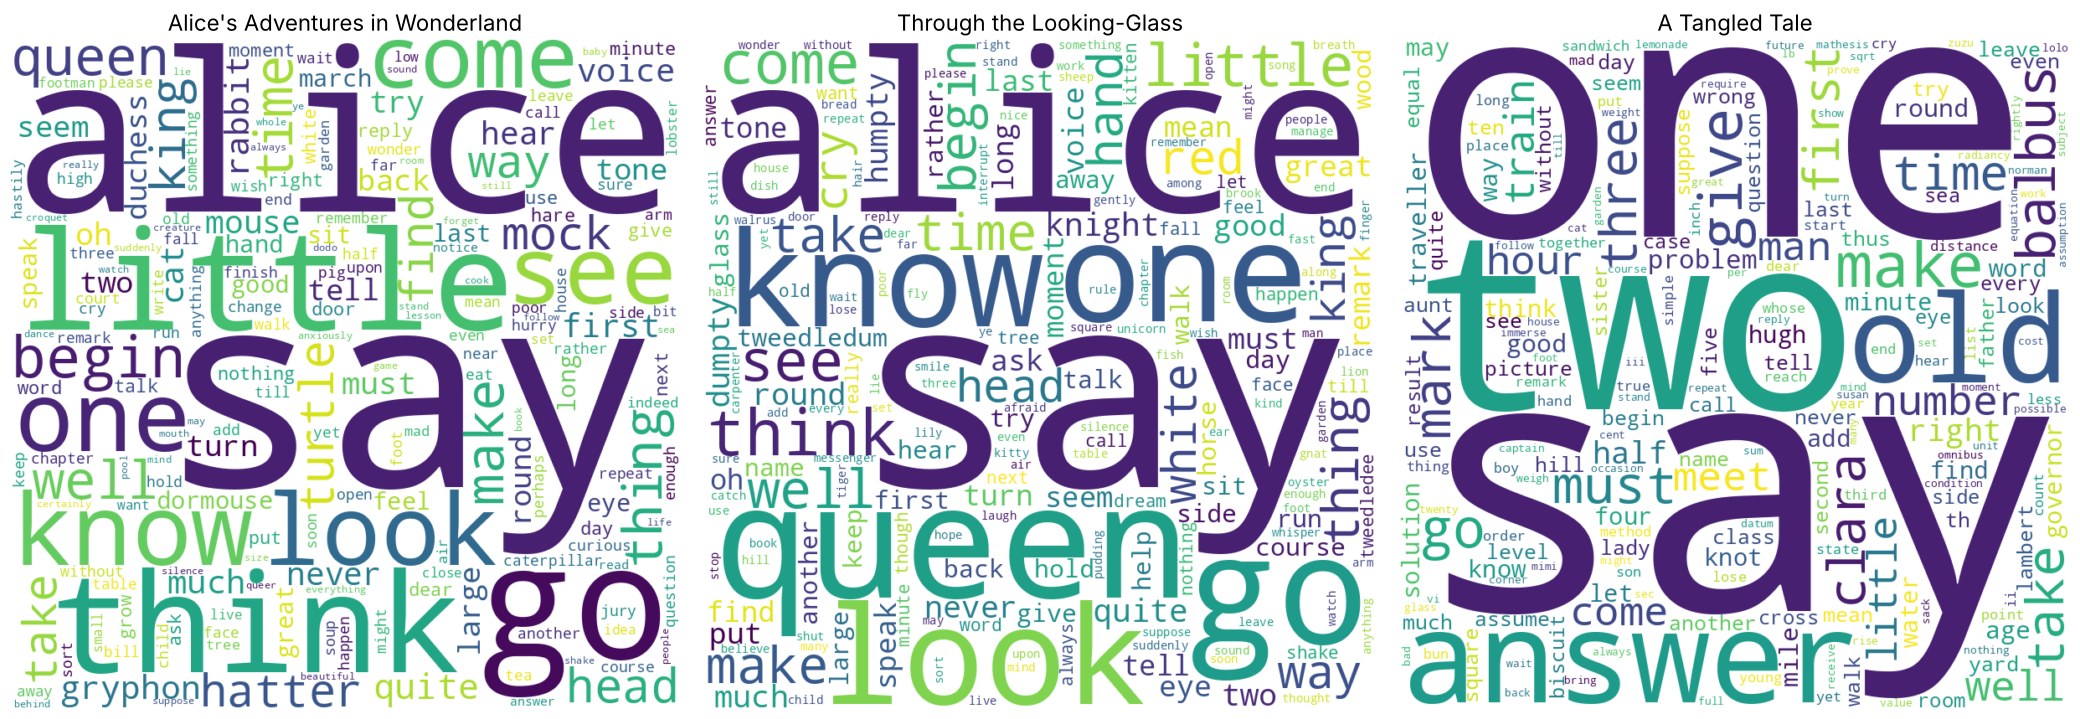

In [13]:
from wordcloud import WordCloud

fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, title, lemmas in zip(axes, TITLES, lemmatized):
    wc = WordCloud(width=800, height=800, background_color="white", colormap="viridis",
                   random_state=42, collocations=False).generate(" ".join(lemmas))
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(title, fontsize=16)
plt.tight_layout(); plt.show()

### 2. Bag of Words: the five most frequent words across all books
**Which text should we use?** Not the raw text: it would be dominated by stopwords (*the, and, to, she…*) and inflections would split counts (*said/say/says*). Stems merge inflections but give non-words that are hard to read (*alic, littl, queen*). The best input is the **lemmatized text without stopwords**: real dictionary words with the inflected forms merged.

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

docs = [" ".join(l) for l in lemmatized]          # one document per book
count_vec = CountVectorizer()
bow = count_vec.fit_transform(docs)
vocab = count_vec.get_feature_names_out()
print("BoW matrix shape (documents x vocabulary):", bow.shape)

total = np.asarray(bow.sum(axis=0)).ravel()
top5_idx = total.argsort()[::-1][:5]
top5 = pd.DataFrame({"word": vocab[top5_idx], "vocab index": top5_idx, "total count": total[top5_idx],
                     **{t: bow[i].toarray().ravel()[top5_idx] for i, t in enumerate(TITLES)}})
top5

BoW matrix shape (documents x vocabulary): (3, 4519)


,word,vocab index,total count,Alice's Adventures in Wonderland,Through the Looking-Glass,A Tangled Tale
0,say,3392,1309,530,545,234
1,alice,116,869,399,468,2
2,one,2739,474,105,155,214
3,go,1710,438,180,187,71
4,get,1678,319,113,151,55


### 3. Print the BoW and read the numbers

In [15]:
print("Printed BoW (first 40 vocabulary columns of each document):")
print(bow[:, :40])        # scikit-learn sparse format: (document, word index)  count
print()
for word in ["alice", "say", "queen", "king", "knight", "clara"]:
    idx = count_vec.vocabulary_[word]
    print(f"'{word}' has index {idx:5d} -> counts per document {bow[:, idx].toarray().ravel().tolist()}")

Printed BoW (first 40 vocabulary columns of each document):
<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 50 stored elements and shape (3, 40)>
  Coords	Values
  (0, 39)	5
  (0, 3)	1
  (0, 32)	1
  (0, 20)	1
  (0, 11)	2
  (0, 2)	1
  (0, 28)	2
  (0, 6)	1
  (0, 29)	1
  (0, 31)	1
  (0, 33)	1
  (0, 23)	1
  (0, 21)	2
  (1, 39)	8
  (1, 3)	6
  (1, 28)	1
  (1, 21)	1
  (1, 18)	1
  (1, 38)	1
  (2, 39)	4
  (2, 32)	1
  (2, 11)	1
  (2, 28)	6
  (2, 21)	1
  (2, 18)	1
  (2, 24)	1
  (2, 15)	1
  (2, 4)	1
  (2, 25)	3
  (2, 5)	1
  (2, 30)	1
  (2, 14)	1
  (2, 36)	1
  (2, 17)	1
  (2, 8)	3
  (2, 7)	1
  (2, 19)	1
  (2, 1)	1
  (2, 26)	4
  (2, 0)	2
  (2, 16)	2
  (2, 37)	1
  (2, 34)	1
  (2, 27)	2
  (2, 22)	3
  (2, 13)	1
  (2, 10)	1
  (2, 35)	2
  (2, 9)	1
  (2, 12)	1

'alice' has index   116 -> counts per document [399, 468, 2]
'say' has index  3392 -> counts per document [530, 545, 234]
'queen' has index  3118 -> counts per document [76, 190, 9]
'king' has index  2164 -> counts per document [64, 69,

**How to read the BoW printout `(d, i)  n`:**
- **d = document number**: 0 = *Alice's Adventures in Wonderland*, 1 = *Through the Looking-Glass*, 2 = *A Tangled Tale* (the order of `docs`).
- **i = index of the word** in the vocabulary (`count_vec.vocabulary_` / `get_feature_names_out()`, sorted alphabetically).
- **n = how many times** that word appears in that document.

Only non-zero entries are stored (sparse matrix). For example the line for `say` in document 0 shows how often *say/said/says* appears in *Alice in Wonderland*.

### 4. Pie plot of the 5 most frequent words

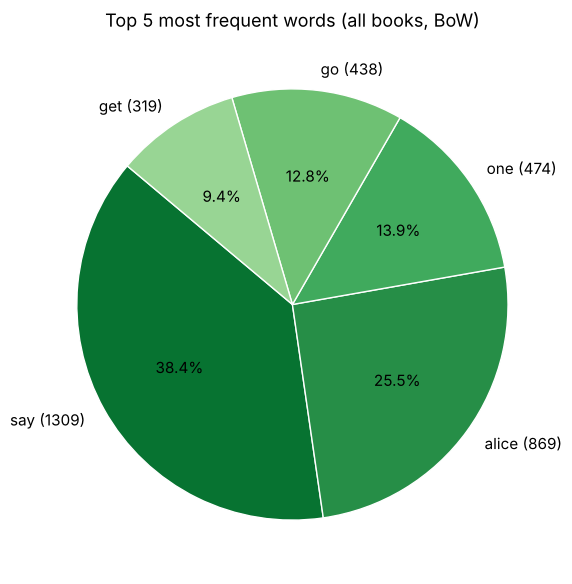

In [16]:
def pie_top_words(words, values, title, ax=None, fmt="{:d}"):
    ax = ax or plt.gca()
    labels = [f"{w} ({fmt.format(v)})" for w, v in zip(words, values)]
    colors = plt.cm.Greens(np.linspace(0.85, 0.4, len(words)))
    ax.pie(values, labels=labels, autopct="%1.1f%%", startangle=140, colors=colors,
           textprops={"fontsize": 11}, wedgeprops={"edgecolor": "white"})
    ax.set_title(title, fontsize=13)

plt.figure(figsize=(7, 7))
pie_top_words(top5["word"], top5["total count"].astype(int), "Top 5 most frequent words (all books, BoW)")
plt.show()

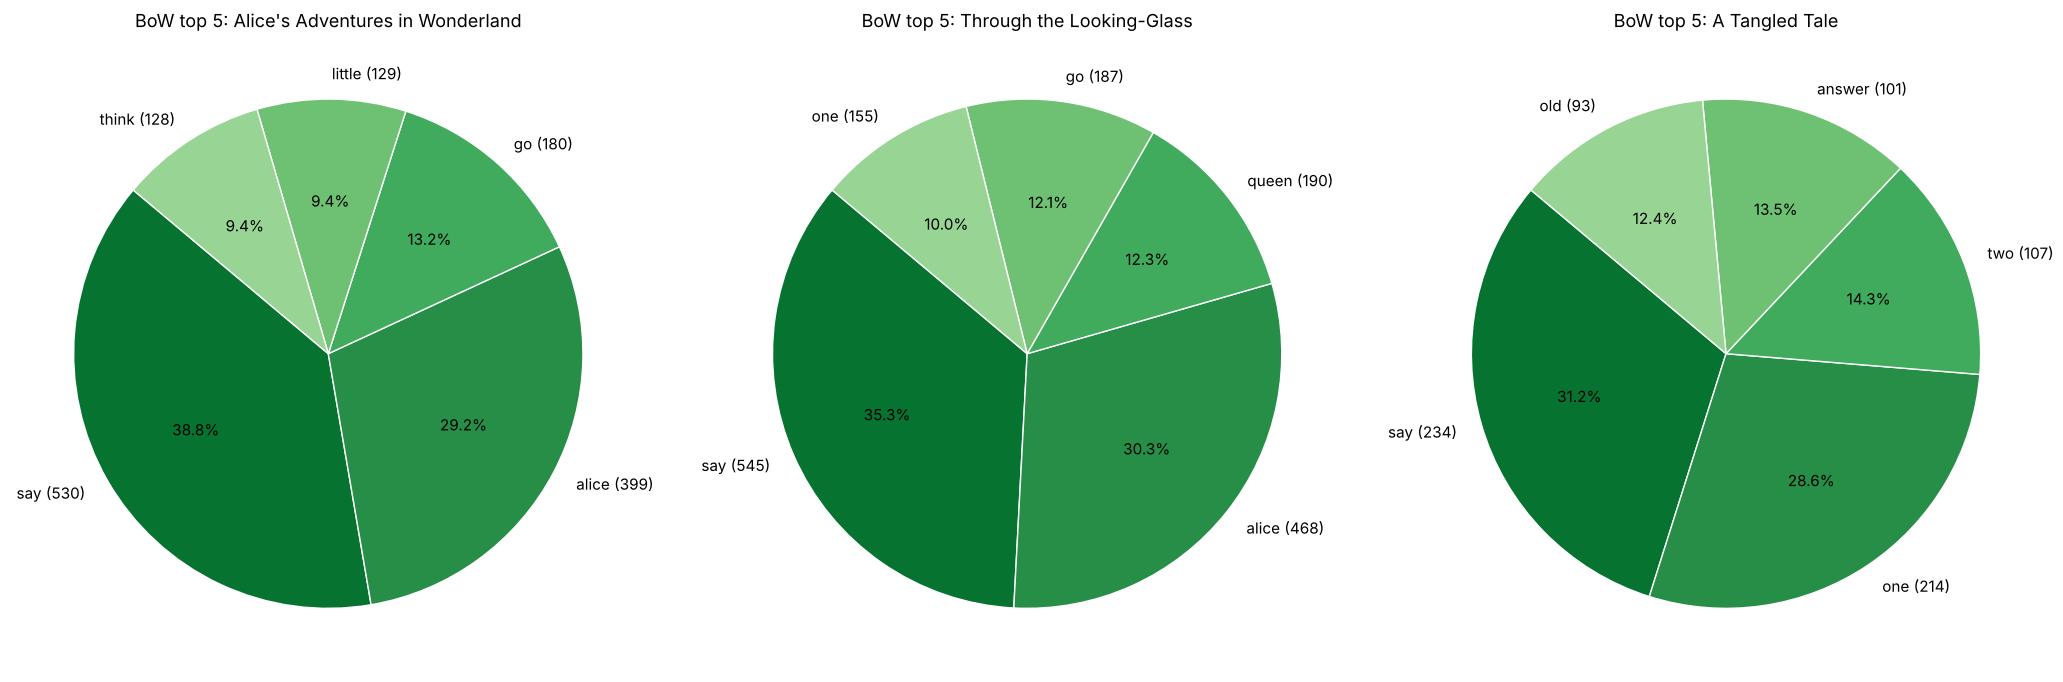

In [17]:
# The same per book, for comparison with TF-IDF later
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for d, (ax, title) in enumerate(zip(axes, TITLES)):
    row = bow[d].toarray().ravel()
    idx = row.argsort()[::-1][:5]
    pie_top_words(vocab[idx], row[idx].astype(int), f"BoW top 5: {title}", ax)
plt.tight_layout(); plt.show()

### 5. Analysis: are those words informative?
The five most frequent words across the three books are **say (1 309), alice (869), one (474), go (438), get (319)**.
- **Expected, not insightful.** `say` is the verb used for every line of dialogue (*said Alice*, *said the Hatter*…), and `go`, `get` and `one` are generic, high-frequency words that would rank near the top in almost any English novel. They tell us these are narrative books with a lot of dialogue, but nothing about what they are about.
- `alice` is informative only to a limited degree. It identifies the protagonist of two books (399 and 468 occurrences) but appears just twice in *A Tangled Tale*. The overall top 5 is dominated by the two Alice books, which hides the third book entirely.
- The per-book pies and the word clouds show the same thing: *Alice in Wonderland* and *Through the Looking-Glass* share almost the same top words (say, alice, go, think, little…). *A Tangled Tale* stands out with `one`, `two` and `answer`. That fits a book of mathematical puzzles ("knots") with numbers and solutions, but those words are still generic.

Raw frequency rewards words that are frequent **everywhere**. To find what makes each book specific, we need to weight words by how distinctive they are: TF-IDF.

# Part 3 · Solving the frequency problem using TF-IDF

### 1. TF-IDF BoW
`min_df=1, max_df=2`: with only 3 documents, an integer `max_df=2` means "**ignore words that appear in more than 2 documents**", so words present in all three books (*say, go, little, think, time…*) are removed. The remaining words get an IDF weight that is higher when they appear in only one book.

In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vec = TfidfVectorizer(min_df=1, max_df=2)
tfidf = tfidf_vec.fit_transform(docs)
tfidf_vocab = tfidf_vec.get_feature_names_out()
print("TF-IDF matrix shape:", tfidf.shape, "(vs", bow.shape, "for the plain BoW)")
print(f"Words removed because they appear in all 3 books: {bow.shape[1] - tfidf.shape[1]}")
removed = sorted(set(vocab) - set(tfidf_vocab), key=lambda w: -total[count_vec.vocabulary_[w]])
print("Most frequent removed words:", removed[:20])
print()
print(tfidf[:1, :40])

TF-IDF matrix shape: (3, 3748) (vs (3, 4519) for the plain BoW)
Words removed because they appear in all 3 books: 771
Most frequent removed words: ['say', 'alice', 'one', 'go', 'get', 'think', 'little', 'know', 'look', 'would', 'queen', 'come', 'make', 'like', 'see', 'well', 'could', 'time', 'begin', 'two']

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 10 stored elements and shape (1, 40)>
  Coords	Values
  (0, 3)	0.004599138155350611
  (0, 30)	0.004599138155350611
  (0, 20)	0.006047313981712012
  (0, 11)	0.009198276310701222
  (0, 2)	0.006047313981712012
  (0, 6)	0.006047313981712012
  (0, 27)	0.006047313981712012
  (0, 29)	0.006047313981712012
  (0, 31)	0.006047313981712012
  (0, 22)	0.006047313981712012


In [19]:
tfidf_top = {}
for d, title in enumerate(TITLES):
    row = tfidf[d].toarray().ravel()
    idx = row.argsort()[::-1][:5]
    tfidf_top[title] = list(zip(tfidf_vocab[idx], row[idx].round(3)))
pd.DataFrame({t: [f"{w} ({s})" for w, s in v] for t, v in tfidf_top.items()}, index=range(1, 6))

,Alice's Adventures in Wonderland,Through the Looking-Glass,A Tangled Tale
1,gryphon (0.333),humpty (0.355),balbus (0.318)
2,rabbit (0.327),dumpty (0.355),clara (0.282)
3,turtle (0.285),knight (0.284),problem (0.201)
4,mock (0.262),tweedledum (0.234),train (0.18)
5,hatter (0.262),tweedledee (0.184),solution (0.17)


### 2. Pie plots of the 5 most relevant words per document

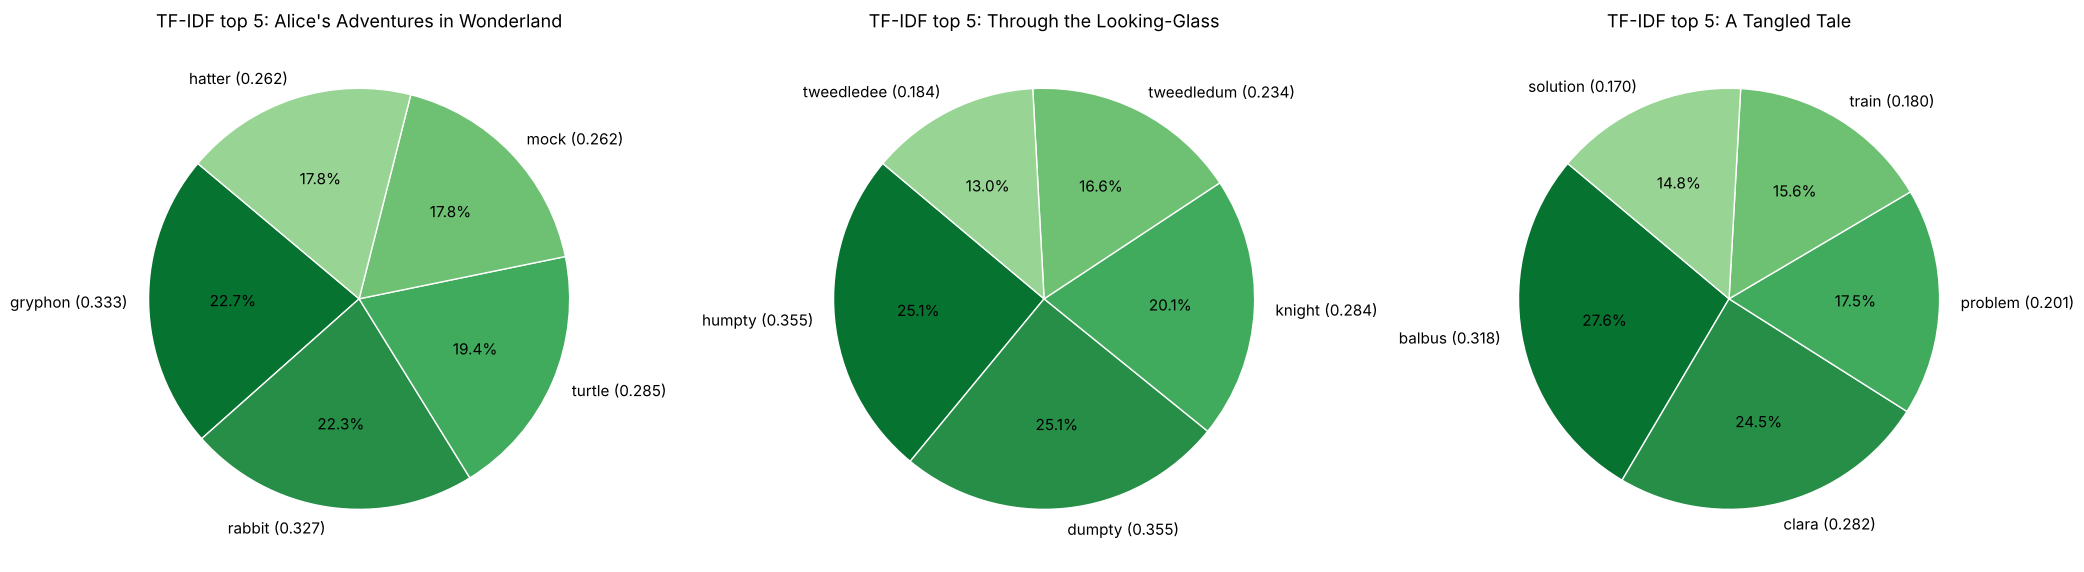

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, (title, items) in zip(axes, tfidf_top.items()):
    words, scores = zip(*items)
    pie_top_words(words, scores, f"TF-IDF top 5: {title}", ax, fmt="{:.3f}")
plt.tight_layout(); plt.show()

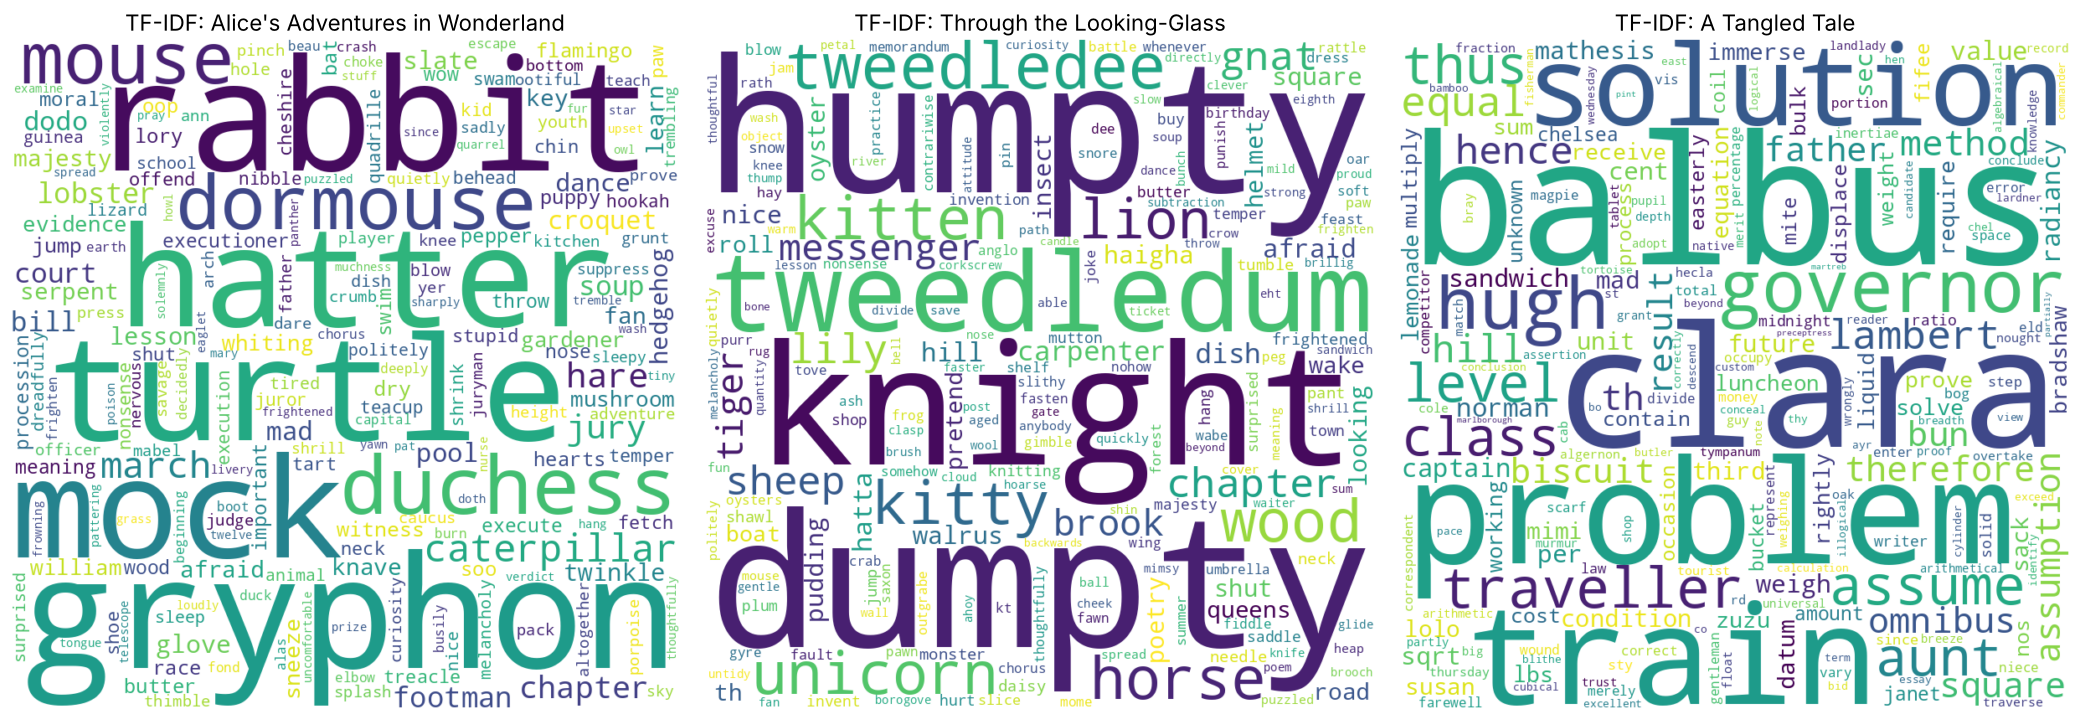

In [21]:
# Bonus: TF-IDF word clouds (weights instead of raw counts)
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for d, (ax, title) in enumerate(zip(axes, TITLES)):
    row = tfidf[d].toarray().ravel()
    weights = {w: s for w, s in zip(tfidf_vocab, row) if s > 0}
    wc = WordCloud(width=800, height=800, background_color="white", random_state=42).generate_from_frequencies(weights)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"TF-IDF: {title}", fontsize=16)
plt.tight_layout(); plt.show()

### Analysis: BoW vs TF-IDF
With `max_df=2`, the **771 words that appear in all three books** are removed, including every word of the previous top 5 (`say, alice, one, go, get`) and generic words such as `think, little, know, look, queen, time`. The remaining words are weighted by `tf × idf`, where words found in only one book get the highest IDF.

The new top words describe each book much better:
- **Alice's Adventures in Wonderland:** `gryphon, rabbit, turtle, mock, hatter`. These are the characters specific to Wonderland: the (White) Rabbit, the Mock Turtle, the Gryphon and the Hatter.
- **Through the Looking-Glass:** `humpty, dumpty, knight, tweedledum, tweedledee`. These are the characters of the second book: Humpty Dumpty, the White Knight and the twins Tweedledum and Tweedledee.
- **A Tangled Tale:** `balbus, clara, problem, train, solution`. These are its two main characters, plus vocabulary showing that the book is a collection of math problems (one "knot" is about trains) with their solutions.

TF-IDF fixes the frequency problem: instead of "what is frequent", it shows "what is frequent **here** and rare elsewhere", which is far more informative for summarising, comparing or classifying documents.

Two caveats:
1. With only 3 documents the IDF is very coarse: a word is in 1, 2 or 3 books. `max_df=2` is a hard cut, so `queen` is removed even though it is a key character in *Looking-Glass*, just because it also appears 9 times in *A Tangled Tale*.
2. Multi-word names are split into separate tokens (`mock` + `turtle`, `humpty` + `dumpty`). Using n-grams (`ngram_range=(1, 2)`) would keep them together.